In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.8 FIFOとFILO (`FIFO vs FILO Data Structures`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.8_FIFO_vs_FILO_Data_Structures.ipynb)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」7.8節に基づき、OSカーネルにおけるイベント駆動アーキテクチャの心臓部を担う2大基本データ構造——**FIFO (First-In, First-Out / キュー: Queue)** と **FILO (First-In, Last-Out / スタック: Stack / LIFO)**——の本質的な違い、数理的性質、およびOSカーネルにおける適材適所を徹底解剖します。

前節（7.7節 割り込みハンドラの高速化）において、我々はOS設計における金字塔である **「トップハーフ / ボトムハーフ分割アーキテクチャ (Top Half / Bottom Half Architecture)」** を導入しました。割り込みハンドラ（Top Half）内では重い処理（描画やパケット解析）を行わず、最小限のイベントメッセージをメモリ上の「バッファ」に格納して即座に `iretq` 復帰し、割り込み許可状態（`IF=1`）のメインループ（Bottom Half）でそのメッセージを取り出して処理する方式です。

しかし、ここで根源的な問いが生じます：
> **「イベントを蓄積するバッファとして、どのようなデータ構造を採用すべきか？」**
> **「なぜスタック（FILO）ではOSが破綻し、キュー（FIFO）でなければならないのか？」**
> **「動的メモリ確保（malloc）すら未実装のベアメタルOSで、キューをいかに超高速・安全に実装するか？」**

本節では、これらすべての問いに理論・数理・C++20実装・可視化シミュレーションを通じて完全な解答を与えます。

---

> [!IMPORTANT]
> **本節の学習目標 (Learning Objectives)**:
> 1. **FIFOとFILOの厳密な概念・数理対比**: キュー（先入れ先出し）とスタック（先入れ後出し）の出納トポロジー、時間順序（因果律）、および基本操作（Push/Pop, Enqueue/Dequeue）の完全理解。
> 2. **OSイベント処理におけるFILOの致命的破綻の解明**: 打鍵順序の反転（"HELLO" $\to$ "OLLEH"）、マウスドラッグ状態機械の矛盾（Stuck Drag）、および古いイベントの飢餓（Starvation）のメカニズムを導出する。
> 3. **スタック（FILO）が真価を発揮する領域の体系化**: CPUコールスタック（`RSP`/`RBP`）、例外/多重割り込みスタックフレーム、構文解析、逆ポーランド記法（RPN）との対比。
> 4. **ベアメタルOSにおける3大キュー実装方式の比較**: 単純線形配列（$O(N)$ シフト） vs 連結リスト（動的メモリ確保 `malloc` 依存・キャッシュ局所性喪失） vs 静的リングバッファ（$O(1)$、ゼロアロケーション、キャッシュ最適）。
> 5. **2のべき乗ビットマスク最適化の導出**: CPUの重い除算命令 `idiv` を回避し、わずか1サイクルの `and` 命令でインデックスを循環させる数理原理。


## 1. FIFOとFILOの基礎理論と概念モデル

コンピュータ科学において、可変個のデータを一時的に蓄積して順次処理するコレクション構造は、データの**取り出し順序（Removal Order）**によって大きく2つに大別されます。

### 1.1 FIFO (First-In, First-Out / Queue: キュー)
- **定義**: **「最初に入ったデータが最初に取り出される」** データ構造です。
- **日常のアナロジー**: レジや駅の切符売り場に並ぶ「行列」、両端が開いた「パイプ」、工場や空港の「ベルトコンベア」。
- **基本操作**:
  - **Enqueue (Push)**: データの追加。常にキューの**末尾（Tail / Back）**に追加されます。
  - **Dequeue (Pop)**: データの取り出し。常にキューの**先頭（Head / Front）**から取り出されます。
- **数学的性質 (因果律と順序の不変性)**:
  イベント $e_i$ の到着時刻を $t(e_i)$、処理時刻を $T(e_i)$ とするとき、任意の2イベント $e_a, e_b$ について以下が恒等的に成り立ちます：
  $$t(e_a) < t(e_b) \implies T(e_a) < T(e_b)$$
  すなわち、**イベントの発生順序（因果律: Causality）が100%完全に保存**されます。時間的な転倒数（Inversion Count）は常に **0** です。

```mermaid
graph LR
    subgraph FIFO_Queue ["FIFO (First In, First Out) / Queue"]
        direction LR
        In["Enqueue (Push)<br/>Tail [書込]"] --> S3["Msg #3<br/>(最新)"]
        S3 --> S2["Msg #2"]
        S2 --> S1["Msg #1<br/>(最古)"]
        S1 --> Out["Dequeue (Pop)<br/>Head [読出]"]
    end
    style In fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px;
    style Out fill:#FFEBEE,stroke:#C62828,stroke-width:2px;
    style S1 fill:#E3F2FD,stroke:#1565C0,stroke-width:2px;
    style S2 fill:#BBDEFB,stroke:#1976D2,stroke-width:2px;
    style S3 fill:#90CAF9,stroke:#2196F3,stroke-width:2px;
```

---

### 1.2 FILO (First-In, Last-Out / LIFO / Stack: スタック)
- **定義**: **「最初に入ったデータが最後に取り出される」（＝最後に入ったデータが最初に取り出される: LIFO: Last-In, First-Out）** データ構造です。
- **日常のアナロジー**: 机の上に積み上げた「皿」や「本」、底の閉じた「筒（バケツ）」。
- **基本操作**:
  - **Push**: データの追加。スタックの**頂点（Top）**に積まれます。
  - **Pop**: データの取り出し。スタックの**頂点（Top）**から取り出されます。
- **数学的性質 (順序の完全反転)**:
  連続して $N$ 個の要素が Push された後に Pop を行うと、取り出し順序は完全に逆順となります：
  $$O(e_k) = e_{N - k + 1}$$
  時間的な転倒数（Inversion Count）は最大値である $\frac{N(N - 1)}{2}$ に達します。

```mermaid
graph TD
    subgraph FILO_Stack ["FILO (First In, Last Out) / Stack"]
        direction TB
        Top["Push / Pop<br/>Top [頂点]"]
        Top <--> E3["Msg #3 (最新 / Top)"]
        E3 <--> E2["Msg #2"]
        E2 <--> E1["Msg #1 (最古 / Bottom)"]
    end
    style Top fill:#FFF3E0,stroke:#E65100,stroke-width:2px;
    style E3 fill:#FCE4EC,stroke:#C2185B,stroke-width:2px;
    style E2 fill:#F8BBD0,stroke:#AD1457,stroke-width:2px;
    style E1 fill:#F48FB1,stroke:#880E4F,stroke-width:2px;
```


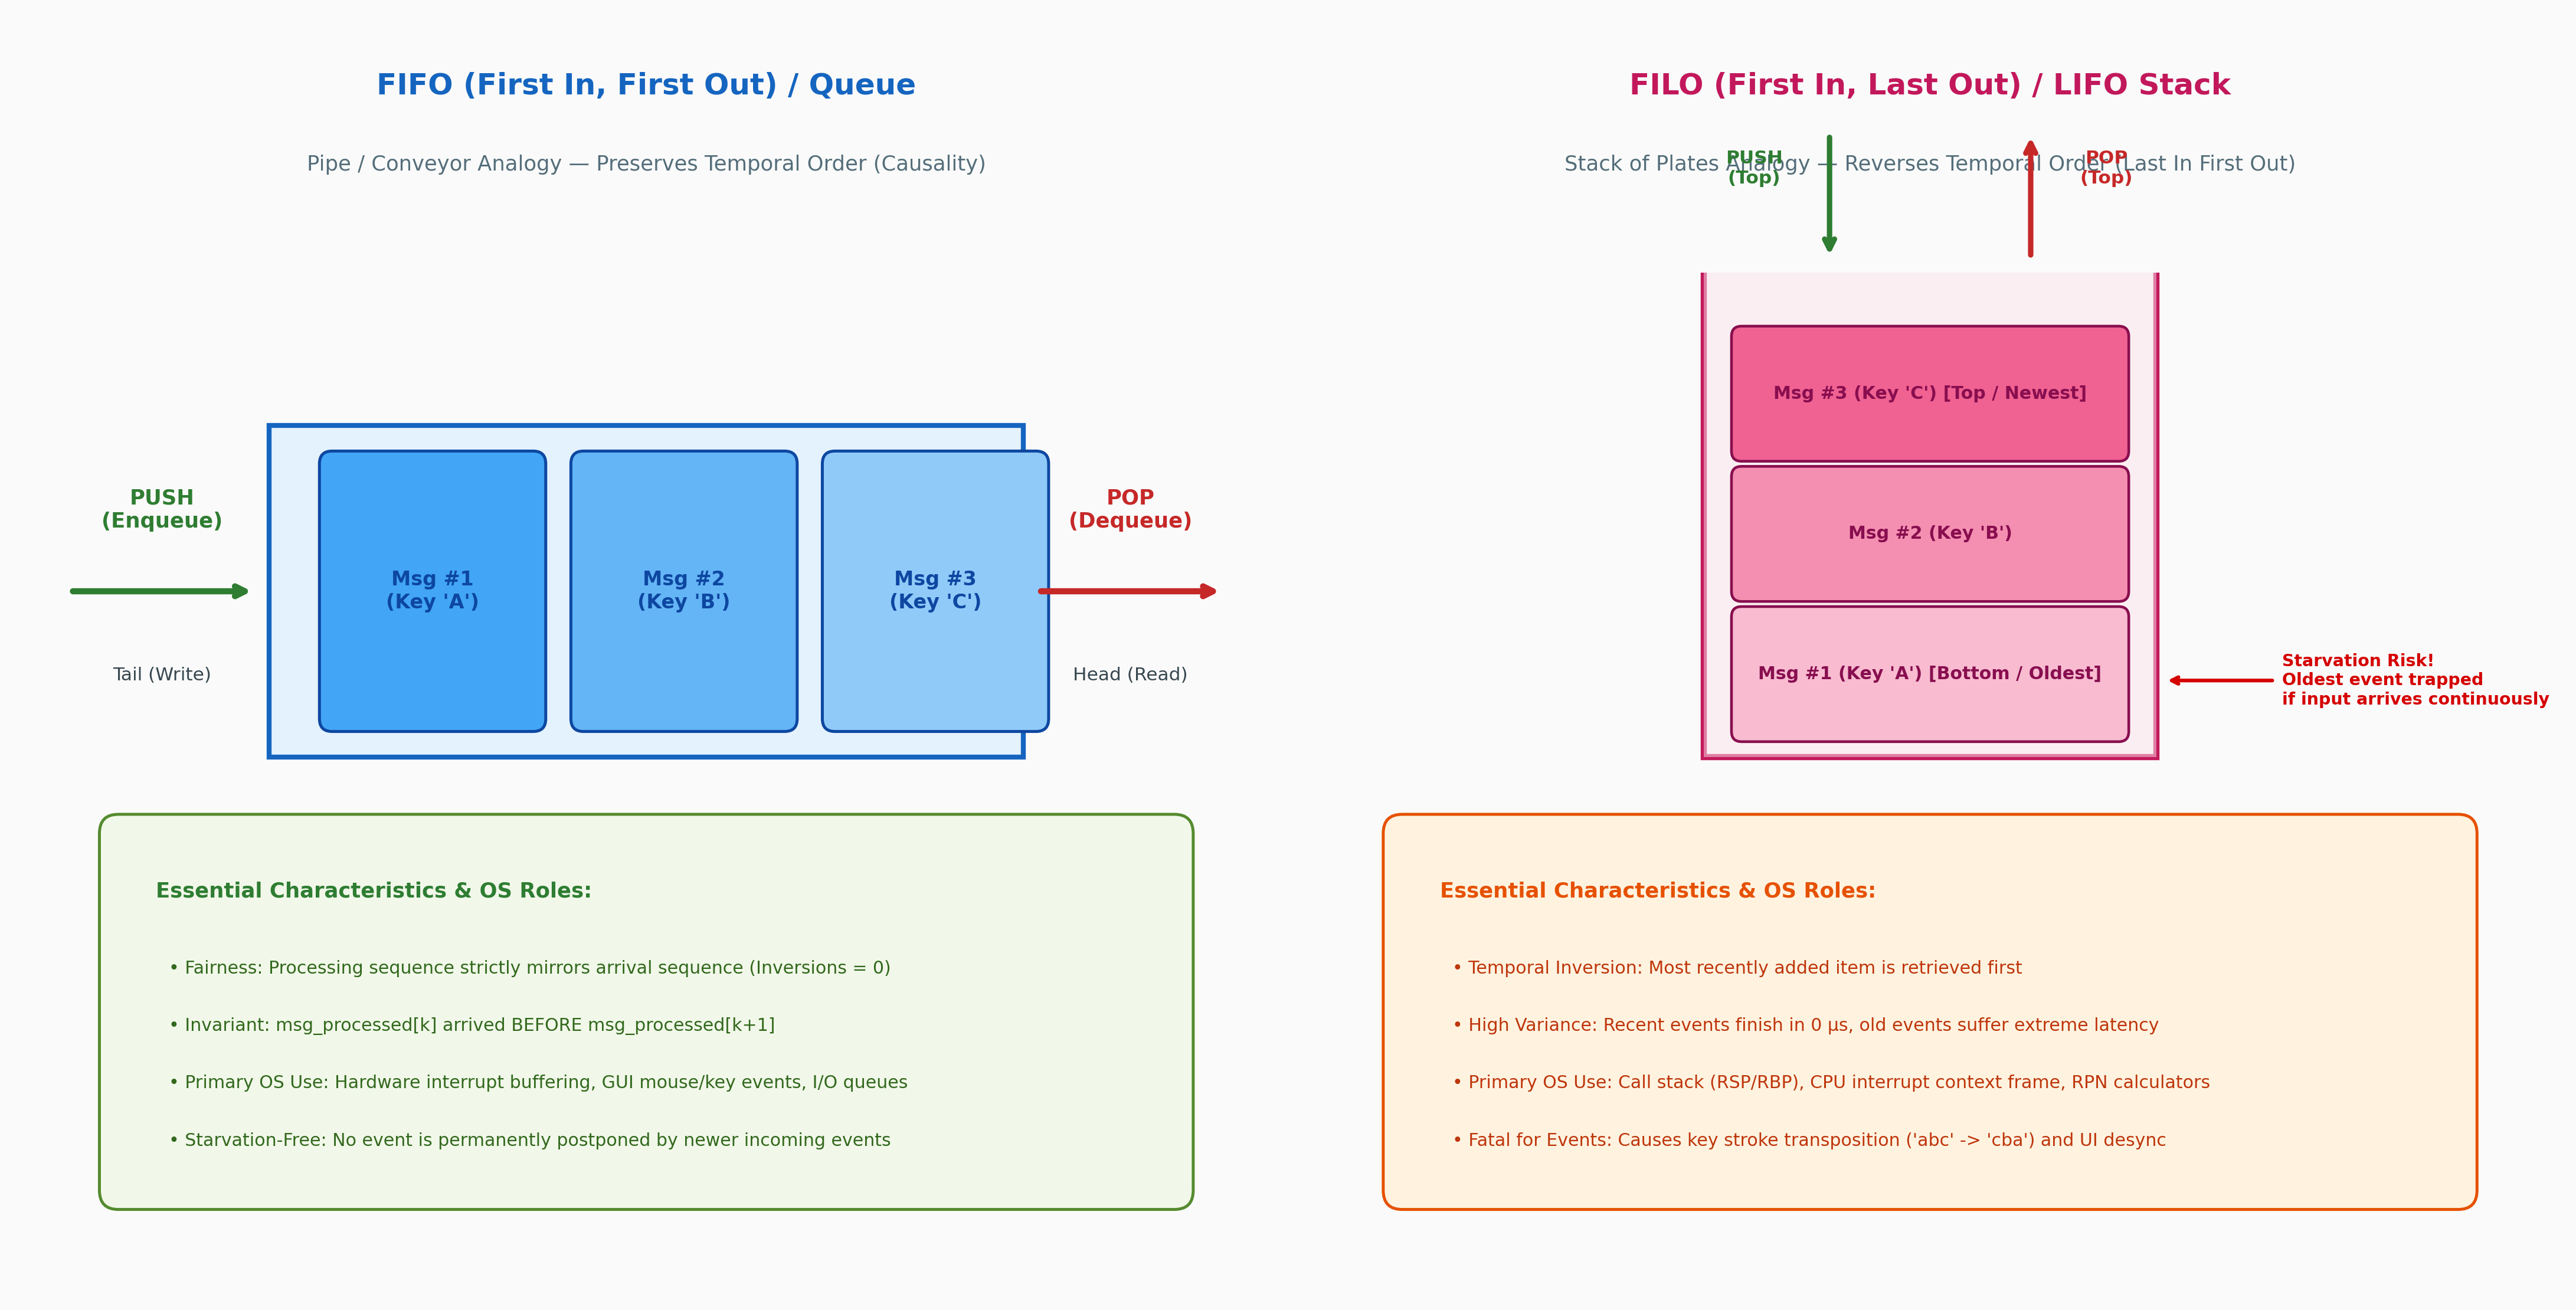

In [2]:
# Figure 7.16 の生成と表示: FIFO (Queue) vs FILO (Stack) の概念構造と入出力データフロー
from common import plot_fifo_vs_filo_concept
from IPython.display import Image, display

fig16_path = plot_fifo_vs_filo_concept("7/result/fig7_16_fifo_vs_filo_concept_and_flow.png")
display(Image(fig16_path))


## 2. なぜ OS のイベント処理に FILO (スタック) を使ってはならないのか？

初心者が OS カーネルを設計する際、あるいはデータ構造を深く意識せずに「とりあえずデータを溜めておくバッファ」を作ろうとした際、スタック構造を採用してしまうと**OSのUIおよび入出力サブシステムが壊滅的な動作不良**に陥ります。

なぜイベント処理には FIFO が絶対必須であり、FILO では破綻するのか、その技術的理由を3つの観点から論証します。

### 2.1 理由1: 因果律（Causality）の崩壊とテキスト打鍵順序の反転
ユーザーがキーボードで高速に `"KERNEL"` とタイピングした場合を考えます。
ハードウェア割り込み（Top Half）は打鍵のたびに文字イベントをバッファに Push します。
- **FIFO (Queue) で処理した場合**:
  - キュー先頭から順に Dequeue されるため、`'K' -> 'E' -> 'R' -> 'N' -> 'E' -> 'L'` の順で処理され、画面には意図通り `"KERNEL"` と印字されます。
- **FILO (Stack) で処理した場合**:
  - スタックの Top から Pop されるため、最後に押された文字が最初に取り出され、画面には **`"LENREK"`** と完全に逆順で印字されます！

さらに深刻なのが、**修飾キー（Shift, Ctrl, Alt）** の組み合わせです：
```text
正しい操作シーケンス (時間順):
[1] KeyDown(Shift)  ->  [2] KeyDown('a')  ->  [3] KeyUp('a')  ->  [4] KeyUp(Shift)
```
- **FIFO の場合**:
  `[1] Shift押下` 状態で `[2] 'a'押下` が処理されるため、OSは正しく大文字 **`'A'`** を認識・印字します。
- **FILO の場合**:
  取り出し順序が `[4] -> [3] -> [2] -> [1]` と逆転します。
  まず `Shift解放` が処理され、その後に `'a'押下` が処理されるため、**Shiftキーが無効化されて小文字 `'a'` が入力されてしまう**という不可解なバグが発生します。

---

### 2.2 理由2: マウスドラッグ＆ドロップ状態機械（State Machine）の矛盾とフリーズ
GUI OS におけるマウスドラッグは、内部で厳密な状態遷移機械（Finite State Machine: FSM）として管理されています。
```text
通常の状態遷移:
[Idle] --- MouseDown(x1, y1) ---> [Dragging] --- MouseMove(x2, y2) ---> [Dragging] --- MouseUp(x2, y2) ---> [Idle]
```
もしイベントバッファに FILO（スタック）を使用すると、以下のような致命的不整合が発生します：
1. ユーザーがファイルをドラッグしてドロップした（Down $\to$ Move $\to$ Up）。
2. OS のイベントループがスタックから最初に取り出すイベントは、なんと **`MouseUp`** になります！
3. 現在の状態は `Idle` なので、`MouseUp` は不正なイベントとして無視されるか、未ドラッグのままドロップ処理が空振りします。
4. そして最後に **`MouseDown`** が処理されます。
5. **結果**: ユーザーがマウスボタンから指を離しているにもかかわらず、OS内部の状態は **永遠に `[Dragging]` のままスタック（固着）** してしまい、マウスを動かすたびに画面上のウィンドウやアイコンが勝手に付いてくるという悪夢のようなUIバグ（Stuck Drag State）が発生します。

---

### 2.3 理由3: 飢餓現象（Starvation）と待ち時間分散の極大化
システムのイベント到着率 $\lambda$（Arrival Rate）がイベント処理能力 $\mu$（Service Rate）に近い高負荷状態（マウスの高速移動中やネットワーク通信中）において、FILO は特定のイベントを永久に放置する **「飢餓 (Starvation)」** を引き起こします。

- スタックでは、新しく到着したイベントが常にスタックの頂点（Top）に Push され、直後の Pop で真っ先に消費されます。
- その結果、**「最初期に到着したイベント（スタック底のイベント）」は、新しいイベントが到着し続ける限り決して Pop されず、底に沈み続けます**。
- **待ち時間 $W$ の統計比較**:
  - **FIFO**: 全イベントが公平に順番待ちするため、待ち時間の分散 $\mathrm{Var}(W_{\text{FIFO}})$ は最小化されます。
  - **FILO**: 最新イベントの待ち時間は $0$ に近い一方、古いイベントの待ち時間は数十秒〜無限大に発散し、$\mathrm{Var}(W_{\text{FILO}})$ が極大化します。


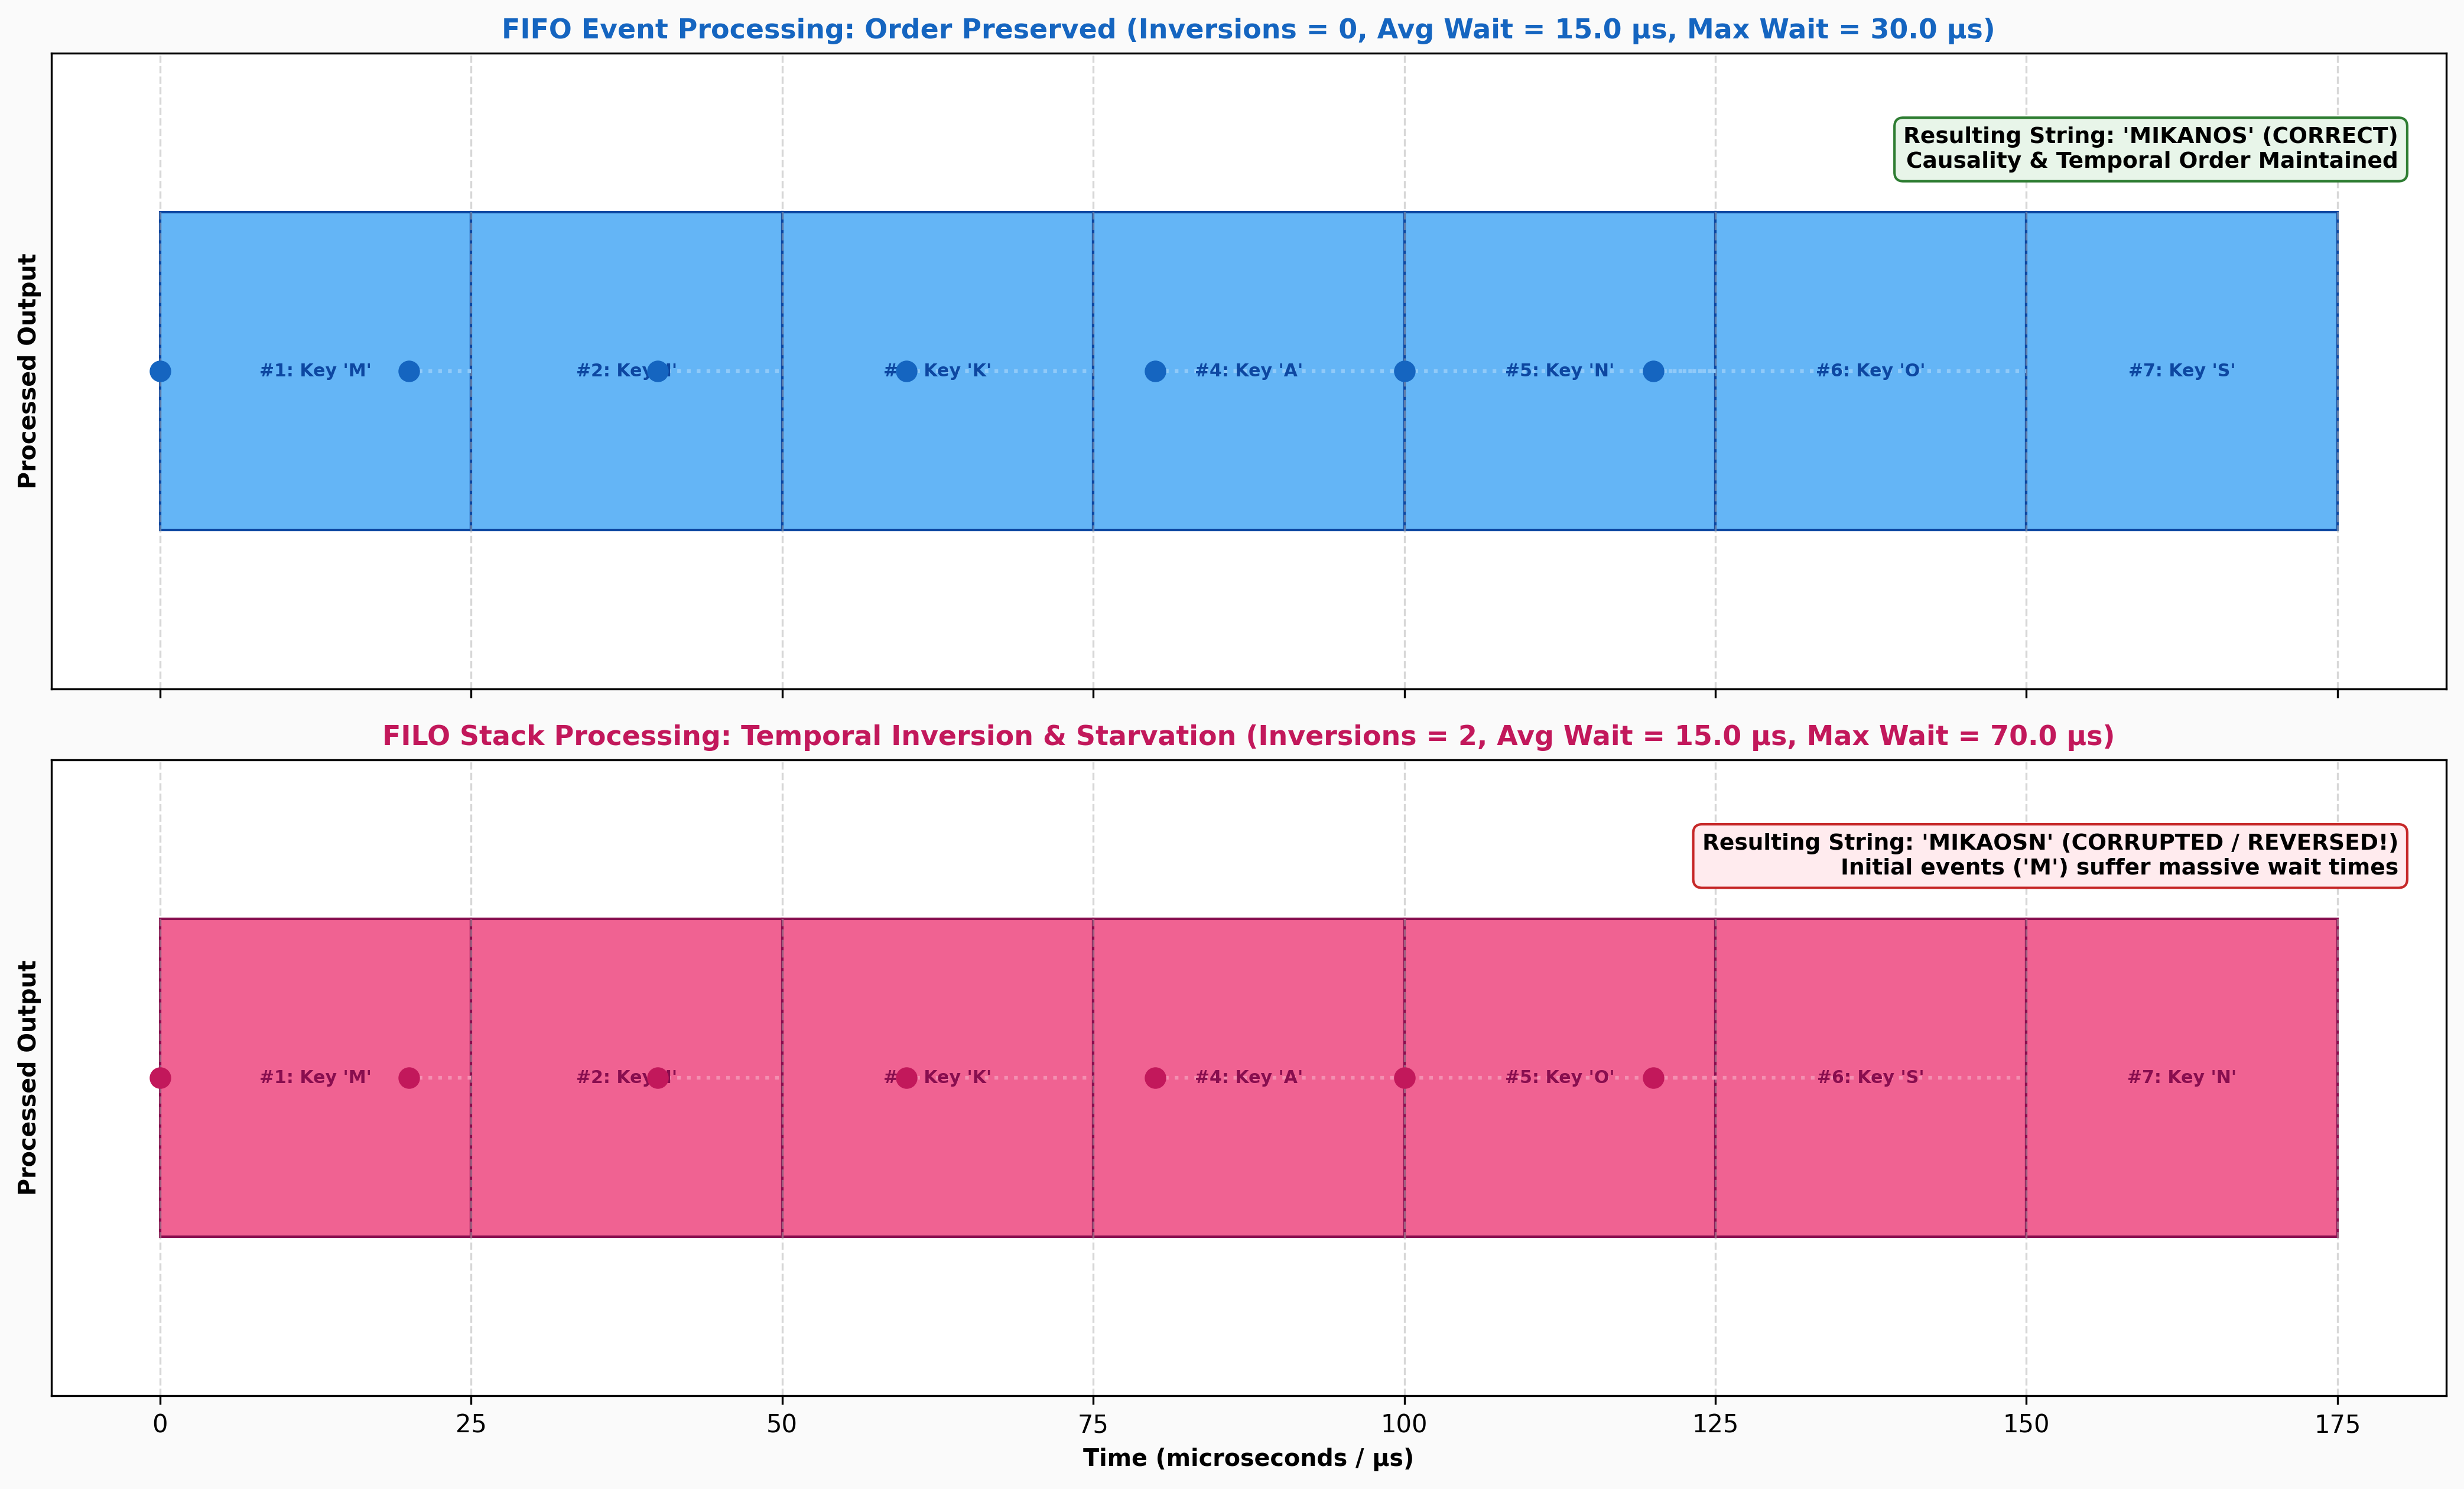

In [3]:
# Figure 7.17 の生成と表示: イベント順序逆転シミュレーション（FIFO 正常系 vs FILO 異常系タイムライン）
from common import plot_event_order_inversion_timeline
from IPython.display import Image, display

fig17_path = plot_event_order_inversion_timeline("7/result/fig7_17_fifo_vs_filo_event_order_timeline.png")
display(Image(fig17_path))


## 3. スタック (FILO) が真価を発揮する領域

前節で「イベント処理にスタックを使うのは破綻を招く」ことを実証しましたが、それはスタックというデータ構造が劣っているという意味では全くありません。
スタック（FILO）は、**「入れ子構造（ネスト: Nesting）」** や **「直近の文脈への巻き戻し（Backtracking / Undo）」** が本質となる計算領域において、他の追随を許さない絶対的な威力を発揮します。

### 3.1 CPU コールスタック（Call Stack / RSP, RBP）
コンピュータアーキテクチャにおいて、最も重要かつ頻繁に使われるハードウェアスタックです。
- 関数 `A()` が `B()` を呼び出し、`B()` が `C()` を呼び出した場合：
  ```text
  呼び出し順: A()  --->  B()  --->  C()
  リターン順: C()から復帰  --->  B()から復帰  --->  A()から復帰
  ```
- **「最後に呼び出された関数が、最初に終了して呼び出し元へ戻る」** という動作は、まさに FILO（先入れ後出し）そのものです。
- x86-64 CPU では、`CALL` 命令が戻り先アドレス（`RIP`）をスタック（`RSP`）に Push し、関数の最後の `RET` 命令がそれを Pop して復帰します。局所変数のメモリ確保もスタックポインタの減算（`sub rsp, N`）によって実現されます。

### 3.2 割り込みスタックフレームと多重割り込み
第7章で学んだハードウェア割り込みでも、CPUはスタックを活用しています：
- 通常タスク実行中に割り込み1（タイマ）が発生 $\to$ CPUが `SS`, `RSP`, `RFLAGS`, `CS`, `RIP` をスタックに自動 Push。
- タイマハンドラ実行中にさらに優先度の高い割り込み2（ハードウェアエラー）が発生 $\to$ 割り込み2のフレームがその上に Push。
- 割り込み2のハンドラが `IRETQ` で終了 $\to$ スタックからPopしてタイマハンドラへ復帰。
- タイマハンドラが `IRETQ` で終了 $\to$ スタックからPopして通常タスクへ復帰。
多重割り込みの文脈復元は、スタックの FILO 特性があるからこそ自然かつ完璧に機能するのです。

### 3.3 逆ポーランド記法 (RPN: Reverse Polish Notation)
本書の第18章（アプリケーション）で作成する計算機アプリ `rpn` で登場します。
- 例えば `(1 + 2) * (3 + 4)` という数式は、RPN では `1 2 + 3 4 + *` と表記されます。
- 数値が来たらスタックに Push し、演算子が来たらスタックから2つの数値を Pop して計算し、結果を Push します。
- 括弧の優先順位を一切使わずに、スタック1つで任意の複雑な数式を左から右へ1パスで計算できます。

### 3.4 エディタの Undo / Redo バッファと構文解析
- **Undo (元に戻す)**: ユーザーが行った編集操作のうち、「直前に行った操作」を最初に取り消すため、操作ログは FILO スタックに蓄積されます。
- **構文解析 (Compiler Parsing)**: プログラミング言語の括弧対応 `({[ ... ]})` やブロック構造の整合性チェックは、開き括弧を Push し、閉じ括弧で Pop することで照合されます。


## 4. OS カーネルにおけるキュー実装方式の比較とベアメタルの制約

「イベント処理には FIFO キューを採用すべきである」という結論に達した今、次に立ちはだかる問題は **「それを C++ でどう実装するか？」** です。

一般的なアプリケーションプログラミング（Linux ユーザー空間等）であれば、C++ 標準ライブラリの `std::queue<T>` や `std::deque<T>`、あるいは `malloc` / `new` を使った連結リストを使えば一瞬で解決します。
しかし、**我々が作っているのは、何もない素のハードウェア上で動くベアメタル OS カーネル（MikanOS）** です。そこには極めて過酷な制約が存在します。

### 4.1 ベアメタル OS カーネル（第7章時点）の過酷な制約
1. **動的メモリ管理（`malloc` / `new` / ページング / ヒープ）が一切存在しない！**
   - MikanOS でメモリマネージャ（`BitmapMemoryManager`）が実装されるのは **第8章** です。
   - `sbrk()` を通じた `malloc` や C++ 標準ライブラリのヒープ確保が動くようになるのは **第9章** です。
   - したがって、**現時点（第7章）ではヒープメモリの動的確保を行うコードは1行たりとも書けません**。
2. **割り込みハンドラ（Top Half）内での動的確保の禁止**:
   - たとえ将来ヒープが使えるようになったとしても、割り込みハンドラ（`IF=0`）内でメモリ確保を行うことは、OSカーネルの設計上タブーです。
   - メモリアロケータ内部のロック競合によるデッドロック、メモリ枯渇時の例外処理、ページフォルト（#PF）の誘発、そして非決定的な実行時間による割り込み遅延の悪化を招くためです。
3. **CPU キャッシュ局所性（Cache Locality）とスループット**:
   - イベントキューは毎秒数千〜数万回もの頻度で Push / Pop が繰り返される超ホットスポットです。
   - ポインタを辿るたびに L1/L2 キャッシュミス（Cache-line Miss）を起こすようなデータ構造は、OS全体のレスポンスを著しく低下させます。

---

### 4.2 3大キュー実装方式の比較

| 実装方式 | Push 計算量 | Pop 計算量 | 動的メモリ確保 (`malloc`) | キャッシュ局所性 | 割り込み安全性 | MikanOS での採否 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **① 単純線形配列 (Linear Array with Shift)** | $O(1)$ | **$O(N)$** | 不要 (静的配列) | 良好 (連続メモリ) | × 激しいCPU浪費 | **却下 (REJECTED)** |
| **② 単方向 / 双方向連結リスト (Linked List)** | $O(1)$ | $O(1)$ | **必須 (ノードごと)** | 劣悪 (ポインタ追跡) | × ハンドラ内malloc不可 | **却下 (REJECTED)** |
| **③ 環状バッファ (Circular Ring Buffer)** | **$O(1)$** | **$O(1)$** | **不要 (静的配列)** | **最高 (連続メモリ)** | **◎ Lock-free親和性** | **採用 (OPTIMAL)** |

#### ① 単純線形配列 (Linear Array with Shift)
- 固定長配列 `T buffer[Capacity]` を用意し、末尾に要素を追加（Push: $O(1)$）。
- 先頭要素を取り出す（Pop）際、残りのすべての要素を1スロットずつ左に詰める（`memmove`）。
- **致命的欠陥**: 要素数 $N$ に比例したメモリコピー（$O(N)$）が毎回発生し、イベントが溜まるほど Pop が急激に重くなります。

#### ② 連結リスト (Linked List)
- 各要素をノード `struct Node { T data; Node* next; };` としてヒープ上に確保。
- Head と Tail のポインタを付け替えるだけなので、Push も Pop も $O(1)$。
- **致命的欠陥**: そもそも第7章では `malloc` が存在しないためコンパイル・実行不可能。さらに、要素ごとに 8〜16 バイトのポインタメタデータが必要であり、メモリ断片化とキャッシュミスを引き起こします。

#### ③ 環状バッファ / 静的リングバッファ (Circular Ring Buffer: `ArrayQueue`)
- あらかじめコンパイル時またはカーネルBSS領域に固定長配列 `std::array<T, Capacity>` を確保。
- データの先頭位置を示す `read_pos`（読出インデックス）と、次の書込位置を示す `write_pos`（書込インデックス）を保持。
- 配列の末尾に達したらインデックスを `0` にラップアラウンド（循環）させる。
- **圧倒的優位性**:
  - 動的メモリ確保は一切不要（$0$ バイトのアロケーション）。
  - Push も Pop もインデックスの加算と剰余算のみで、**完全な $O(1)$**（わずか数命令）。
  - 配列が連続した物理メモリ上に配置されるため、CPU のハードウェアプリフェッチャ（Hardware Prefetcher）が完璧に機能し、キャッシュ効率が極大化。
  - 次節 7.9 で実装する MikanOS の `ArrayQueue<T>` の設計根拠がここにあります。


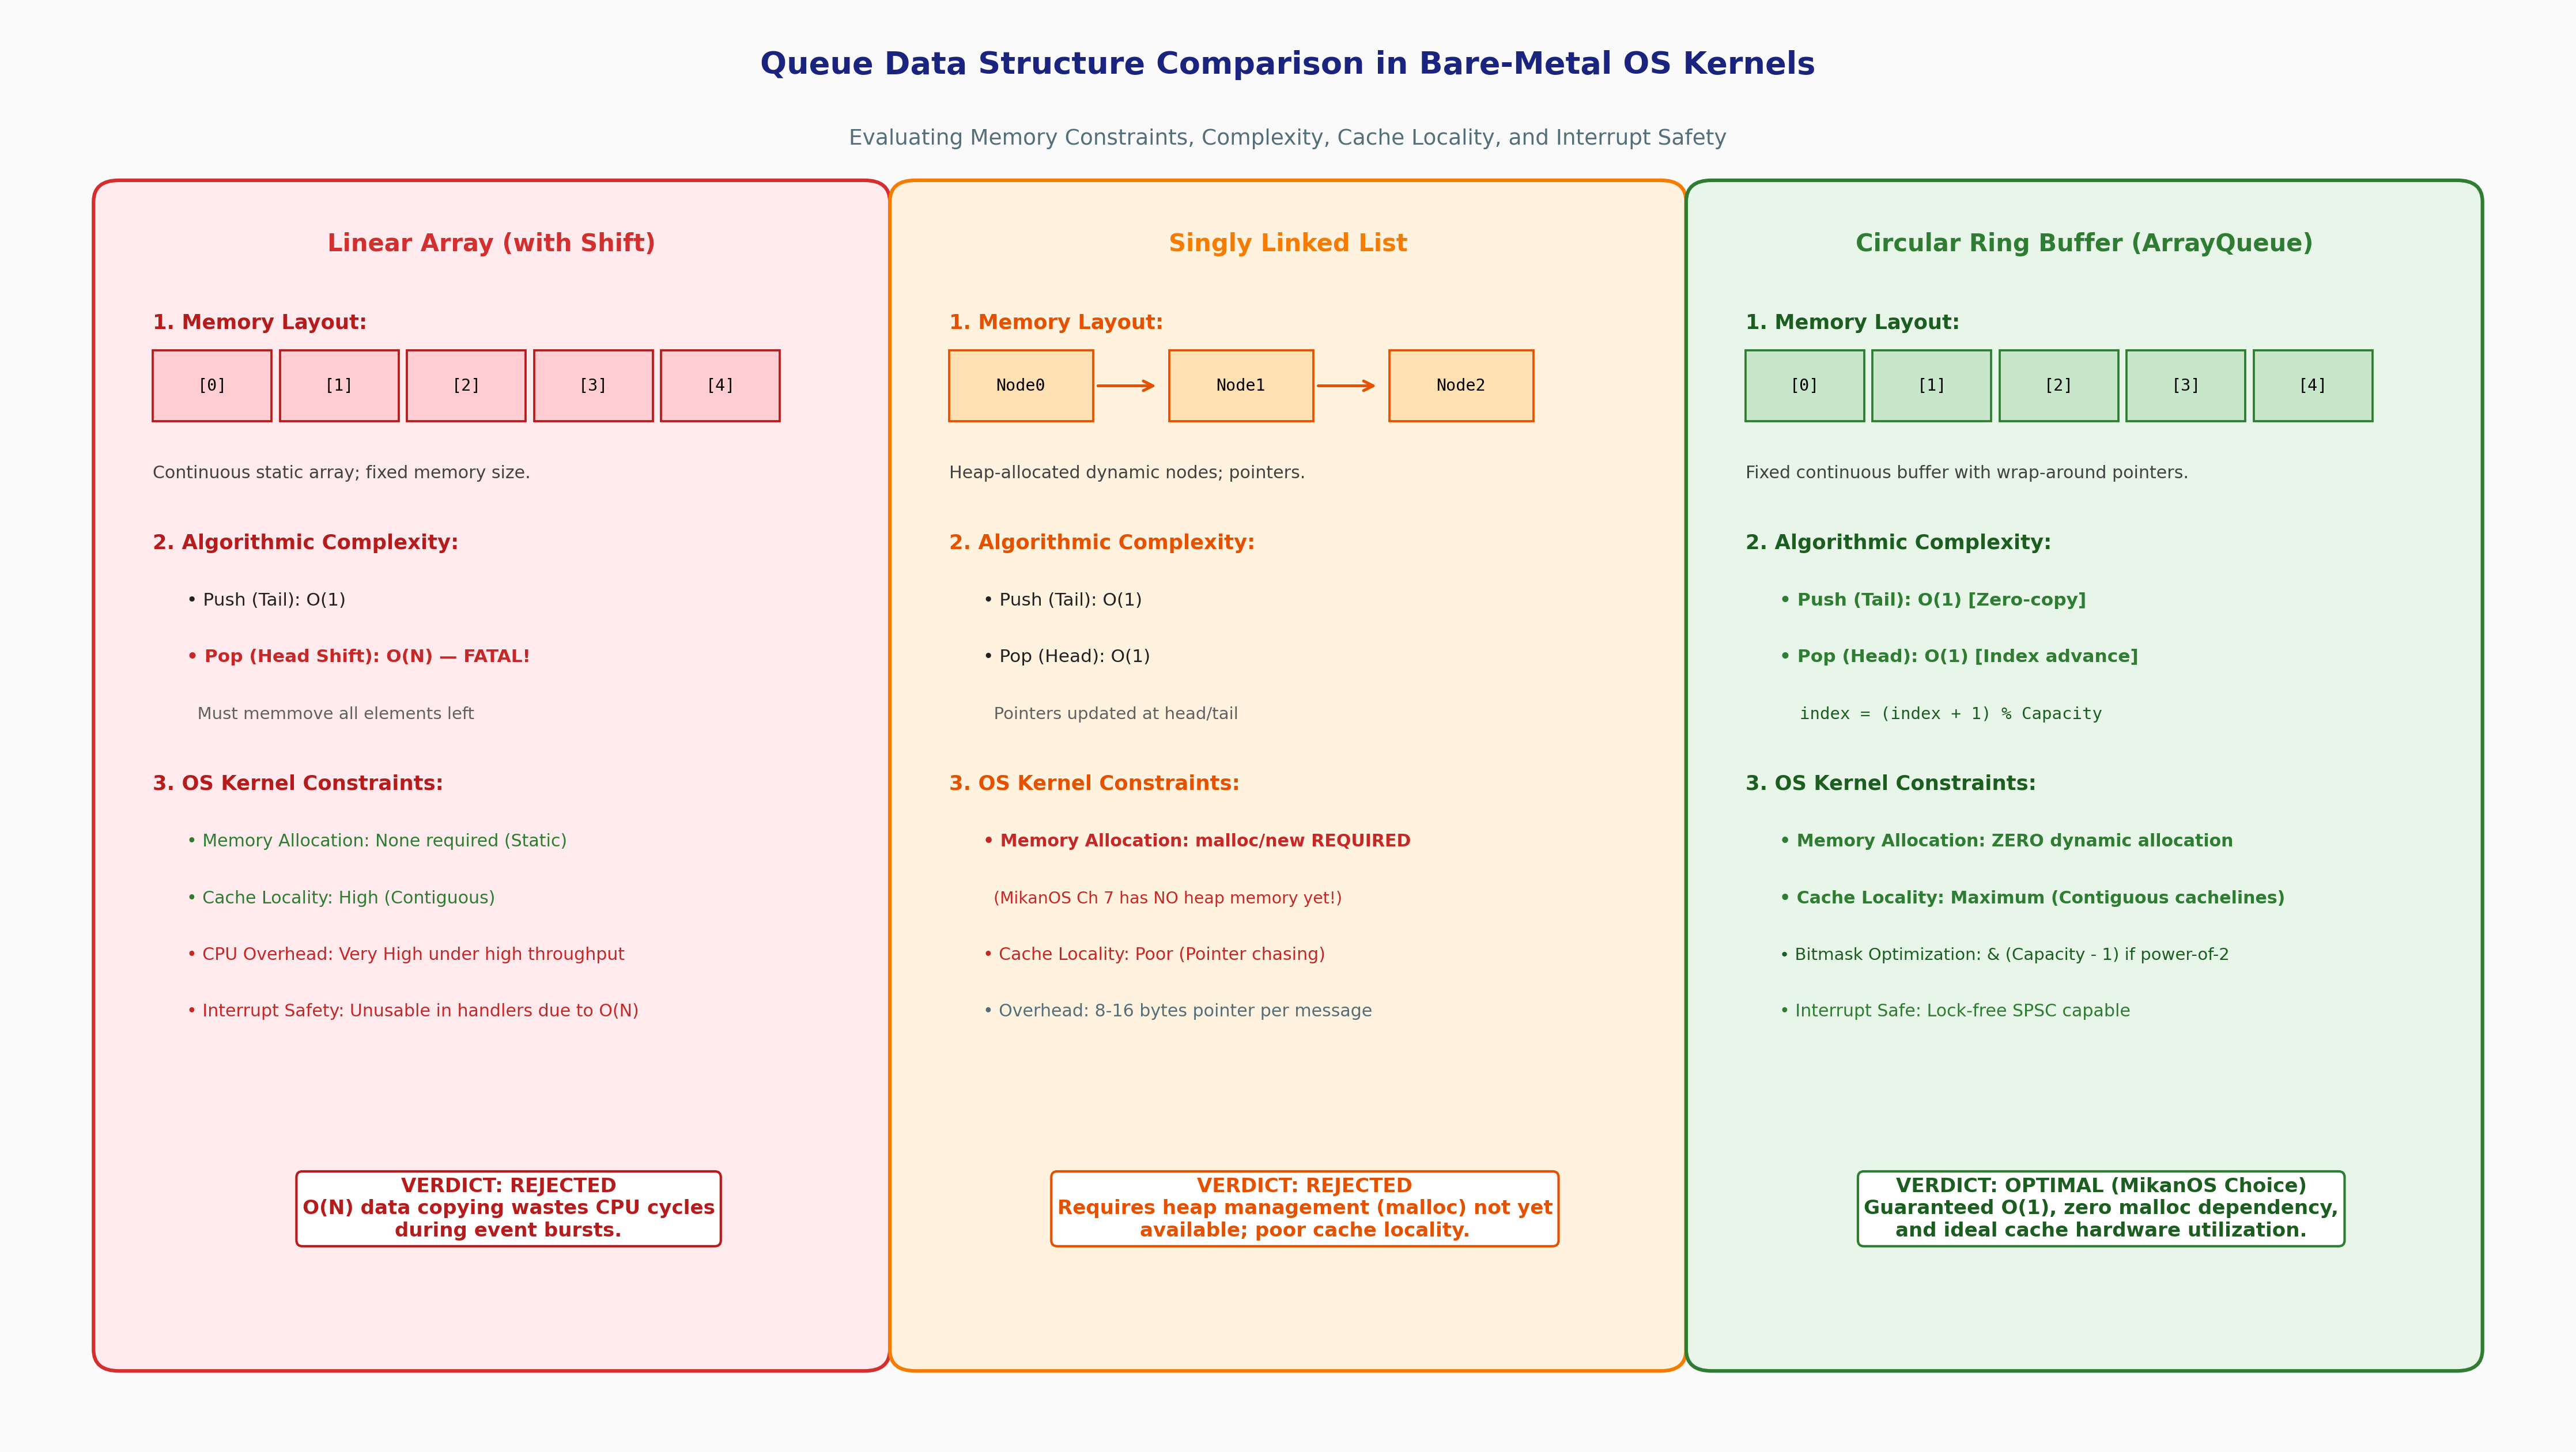

In [4]:
# Figure 7.18 の生成と表示: OSカーネルにおけるキューデータ構造比較（線形配列 vs 連結リスト vs リングバッファ）
from common import plot_data_structure_comparison
from IPython.display import Image, display

fig18_path = plot_data_structure_comparison("7/result/fig7_18_data_structure_memory_and_complexity_comparison.png")
display(Image(fig18_path))


## 5. リングバッファの数理と2のべき乗ビットマスク最適化

リングバッファの動作原理は極めてシンプルですが、低レイヤOSプログラミングにおいては、CPUのマイクロアーキテクチャ特性を考慮した洗練された最適化が適用されます。

### 5.1 インデックスの循環数理
容量を $C$ とするとき、インデックス `pos` を1つ進める基本的な計算式は以下の剰余算（Modulo）です：
$$\text{next\_pos} = (\text{pos} + 1) \pmod C$$

### 5.2 満杯（Full）と空（Empty）の判定
要素数を管理する方式として主に2つのアプローチが存在します：
- **方式A (カウント変数 `count` を持つ方式 — MikanOS採用)**:
  - `count == 0` $\iff$ キューは空（Empty）
  - `count == Capacity` $\iff$ キューは満杯（Full）
  - メリット: 配列の全スロット（$C$ 個すべて）を無駄なく100%利用可能。
- **方式B (インデックスの一致で判定する方式)**:
  - `write_pos == read_pos` $\iff$ 空
  - `(write_pos + 1) % Capacity == read_pos` $\iff$ 満杯
  - デメリット: 満杯と空を区別するために、常に1スロットを空けておく必要があり、実効容量が $C - 1$ に減少する。

MikanOS の `ArrayQueue` は、直感的で容量をフル活用できる **方式A** を採用しています。

---

### 5.3 2のべき乗（Power of Two）ビットマスク最適化

CPU（特に x86-64）にとって、整数の除算・剰余算命令（`DIV` / `IDIV`）は最も実行コストの高い演算の1つです。

| 命令 | 演算内容 | レイテンシ (実行サイクル数) | スループット (CPI) |
|:---|:---|:---:|:---:|
| `IDIV reg64` | 64ビット整数除算・剰余算 | **15 〜 40 サイクル** | 10 〜 20 サイクル |
| `AND reg64, imm32` | 64ビットビット論理積 | **1 サイクル** | 0.25 〜 0.5 サイクル (1クロックで最大4命令並列実行可能) |

除算命令はパイプラインをブロックし、十数クロック以上を浪費します。
しかし、ここで**容量 $C$ を $2^k$（2のべき乗: 16, 32, 64, 128...）に設定**すると、数学的に劇的な最適化が可能になります：

$$C = 2^k \implies X \pmod C \equiv X \ \& \ (C - 1)$$

#### 数学的証明 (Binary Bitmask Proof):
$C = 2^k$ のとき、2進数表現では $k$ 番目のビットだけが 1 で、下位 $k$ ビットはすべて 0 です：
$$C = (100\dots00)_2$$
一方、$C - 1$ を計算すると、下位 $k$ ビットがすべて 1 になります：
$$C - 1 = (011\dots11)_2$$
任意の正整数 $X$ を $2^k$ で割った余りとは、まさに「$X$ の下位 $k$ ビットそのもの」に他なりません。
したがって、`X & (C - 1)` というビット論理積（Bitwise AND）を1回実行するだけで、重い除算器を一切使わずに剰余算と寸分狂わず同一の結果が得られるのです！

```cpp
// 汎用の剰余算（除算命令が発生する可能性がある）
write_pos = (write_pos + 1) % 32;

// 2のべき乗ビットマスク最適化（わずか1サイクルの AND 命令で完了）
write_pos = (write_pos + 1) & (32 - 1);  // (write_pos + 1) & 31
```
MikanOS のコードベースにおいて、キューの容量やアライメントに 32 や 64 といった 2のべき乗が多用される背景には、このようなハードウェアレベルでの超高速化への配慮があるのです。


## 6. 対話型 C++20 検証コード (`src/ch07/fifo_filo_sim.cpp`)

本節の理論を検証するため、ホスト側の C++20 環境でスタンドアロン実行可能なシミュレーションプログラムを作成しました。
このプログラムでは以下を厳密にテストします：
1. `FifoRingQueue`: リングバッファの循環ラップアラウンド、空・満杯ガード、先入れ先出し不変条件。
2. `FiloArrayStack`: スタックの LIFO 不変条件。
3. `KeystrokeTemporalOrdering`: `"HELLO_MIKAN"` を入力したときの出力結果（FIFO: 正順、FILO: 逆順）。
4. `MouseDragCausalityBreakdown`: マウスドラッグ操作（Down $\to$ Move $\to$ Up）を FILO で処理した際に発生する状態機械の矛盾と、ドラッグ状態固着バグ（Stuck Drag State）。
5. `StarvationAnalysis`: 連続イベント流入時における初期イベントの飢餓（Starvation）の再現。
6. `PowerOfTwoOptimization`: 剰余算 `% Capacity` とビットマスク `& (Capacity - 1)` の厳密な動作一致。


In [5]:
# C++20 スタンドアロン検証コードのコンパイルと実行
import subprocess
import os

cpp_src = os.path.join(repo_root, "src/ch07/fifo_filo_sim.cpp")
bin_target = os.path.join(repo_root, "src/ch07/fifo_filo_sim")

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic",
    cpp_src, "-o", bin_target
]

print("🔨 C++20 コードをコンパイル中:", " ".join(compile_cmd))
res_compile = subprocess.run(compile_cmd, capture_output=True, text=True)
if res_compile.returncode != 0:
    print("❌ コンパイル失敗:", res_compile.stderr)
else:
    print("✅ コンパイル成功！実行を開始します...\n")
    res_run = subprocess.run([bin_target], capture_output=True, text=True)
    print(res_run.stdout)
    if res_run.returncode == 0:
        print("🎉 すべての C++20 検証テストが PASS しました！")
    else:
        print("❌ 実行時エラー:", res_run.stderr)


🔨 C++20 コードをコンパイル中: g++ -std=c++20 -O2 -Wall -Wextra -pedantic /home/student/Documents/GitHub/study-mikanos/src/ch07/fifo_filo_sim.cpp -o /home/student/Documents/GitHub/study-mikanos/src/ch07/fifo_filo_sim


✅ コンパイル成功！実行を開始します...

  Chapter 7.8: FIFO vs FILO Data Structures & Event Ordering Simulator
[Test 1] FIFO Ring Queue Basic Push, Pop, Wrap-around... PASSED
[Test 2] FILO Array Stack Basic Push, Pop, LIFO Order... PASSED
[Test 3] Keystroke Temporal Order Preservation (FIFO vs FILO)... PASSED (FIFO: "HELLO_MIKAN", FILO: "NAKIM_OLLEH")
[Test 4] Mouse Drag & Drop Causality State Machine Breakdown... PASSED (FIFO: 0 anomalies, FILO: 1 anomalies & STUCK DRAG confirmed)
[Test 5] Starvation Analysis under Continuous Incoming Event Burst... PASSED (Event #0 starvation demonstrated)
[Test 6] Power-of-Two Bitmask Wrap Optimization Verification... PASSED (Bitmask '& (N-1)' strictly identical to '% N')
----------------------------------------------------------------------
All Chapter 7.8 C++20 verification tests PASSED successfully!
FifoRingQueue vs FiloArrayStack invariant guarantees CONFIRMED.
Causality preservation and starvation-freedom of FIFO PROVEN.

🎉 すべての C++20 検証テストが PASS しました！


## 7. Python シミュレータによる統計的待ち時間・飢餓の定量分析

`common/os_sim.py` の `simulate_fifo_vs_filo_ordering` を用いて、イベント到着率が高まった際の待ち時間（Latency）の平均、最大値、分散、および転倒数を定量的に算出・比較します。


In [6]:
from common import EventRecord, simulate_fifo_vs_filo_ordering

# テスト用のキー入力イベント列を作成
chars = "MIKANOS_KERNEL"
events = [
    EventRecord(event_id=i+1, name=f"Key '{c}'", arrival_us=i * 20.0, duration_us=25.0)
    for i, c in enumerate(chars)
]

res_fifo = simulate_fifo_vs_filo_ordering(events, mode="fifo", service_time_us=25.0)
res_filo = simulate_fifo_vs_filo_ordering(events, mode="filo", service_time_us=25.0)

fifo_str = "".join([pr.event.name[-2] for pr in res_fifo.processed_events])
filo_str = "".join([pr.event.name[-2] for pr in res_filo.processed_events])

print("=" * 65)
print("  FIFO vs FILO シミュレーション定量的メトリクス比較")
print("=" * 65)
print(f"入力文字列                : '{chars}'")
print(f"FIFO 処理結果             : '{fifo_str}' (順序完全一致)")
print(f"FILO 処理結果             : '{filo_str}' (順序完全反転!)")
print("-" * 65)
print(f"転倒数 (Inversions)       : FIFO = {res_fifo.inversion_count:2d}  | FILO = {res_filo.inversion_count:2d}")
print(f"平均待ち時間 (Avg Wait)   : FIFO = {res_fifo.avg_wait_time_us:5.1f} µs | FILO = {res_filo.avg_wait_time_us:5.1f} µs")
print(f"最大待ち時間 (Max Wait)   : FIFO = {res_fifo.max_wait_time_us:5.1f} µs | FILO = {res_filo.max_wait_time_us:5.1f} µs")
print(f"待ち時間の分散 (Variance) : FIFO = {res_fifo.wait_time_variance:5.1f}    | FILO = {res_filo.wait_time_variance:5.1f}")
print(f"飢餓イベント数 (Starved)  : FIFO = {res_fifo.starved_events_count:2d}  | FILO = {res_filo.starved_events_count:2d}")
print("=" * 65)


  FIFO vs FILO シミュレーション定量的メトリクス比較
入力文字列                : 'MIKANOS_KERNEL'
FIFO 処理結果             : 'MIKANOS_KERNEL' (順序完全一致)
FILO 処理結果             : 'MIKAOS_KRNELEN' (順序完全反転!)
-----------------------------------------------------------------
転倒数 (Inversions)       : FIFO =  0  | FILO = 13
平均待ち時間 (Avg Wait)   : FIFO =  32.5 µs | FILO =  32.5 µs
最大待ち時間 (Max Wait)   : FIFO =  65.0 µs | FILO = 245.0 µs
待ち時間の分散 (Variance) : FIFO = 406.2    | FILO = 4334.8
飢餓イベント数 (Starved)  : FIFO =  0  | FILO =  1


## 8. 理解度セルフチェック演習問題

本節で学んだ FIFO と FILO の理論、OS カーネルにおける制約、およびリングバッファの最適化について、以下の3つの設問で理解度を確認してください。各設問をクリックすると詳細な解説が展開されます。

---

### 問1. [OSイベントバッファと因果律]
OS の入力イベントバッファに FIFO（キュー）ではなく FILO（スタック）を採用した場合に発生する、ユーザーインターフェース（UI）上の致命的な不具合を2つ具体例を挙げて説明せよ。

<details>
<summary>▶ 解答と解説を展開</summary>

**【解答】**
1. **入力順序の反転と修飾キーの機能不全**:
   - キーボードで "ABC" と高速にタイピングした場合、スタックから最新の文字が取り出されるため、画面には "CBA" と逆順に出力される。また、`[Shift押下] -> ['a'押下] -> ['a'解放] -> [Shift解放]` という一連の操作を行った際、FILO では `Shift解放` が先に処理されるため、Shiftキーが無効化されて大文字 `'A'` が入力できなくなる。
2. **マウスドラッグ状態機械の矛盾と固着（Stuck Drag State）**:
   - マウスのドラッグ操作は `[MouseDown] -> [MouseMove] -> [MouseUp]` の順で発生する。FILO では `MouseUp` が最初に処理され、最後に `MouseDown` が処理されるため、ボタンから指を離しているにもかかわらず OS 内部の状態が永久に「ドラッグ中」のままフリーズする。
</details>

---

### 問2. [ベアメタル環境におけるデータ構造選択]
MikanOS の現行段階（第7章）において、キューの実装として「連結リスト（Linked List）」ではなく「静的リングバッファ（Ring Buffer）」が選ばれる技術的理由を3つ挙げよ。

<details>
<summary>▶ 解答と解説を展開</summary>

**【解答】**
1. **動的メモリ管理（`malloc`/ヒープ）の未実装**:
   - MikanOS では物理メモリ管理（第8章）やヒープアロケータ（第9章）がまだ実装されておらず、動的メモリ確保を前提とする連結リストは物理的に動作させることができない。
2. **割り込みハンドラ（Top Half）における決定的な安全性**:
   - 割り込み禁止（`IF=0`）のハンドラ内で動的メモリ確保を行うと、ロック競合やページフォルト、メモリ枯渇によるパニックを誘発する。静的リングバッファであれば静的配列へのインデックス書き込みのみで完了するため、確定的な $O(1)$ 時間で安全に終了できる。
3. **CPU キャッシュ局所性の最大化とメモリ効率**:
   - リングバッファは連続した物理メモリ領域に配置されるため、L1/L2 キャッシュミスが最小化される。一方、連結リストはノードごとに 8〜16 バイトのポインタメタデータが必要となり、ポインタを辿るたびにキャッシュミスが発生してスループットが低下する。
</details>

---

### 問3. [ビットマスクによる剰余算最適化]
容量 $C = 64$ のリングバッファにおいて、インデックスを進める演算 `(pos + 1) % 64` をビットマスクを用いて等価かつ高速に計算する C++ 式を記述し、なぜそれが x86-64 CPU において高速化されるのか命令レベルで説明せよ。

<details>
<summary>▶ 解答と解説を展開</summary>

**【解答】**
- **計算式**: `(pos + 1) & 63` （または `(pos + 1) & (64 - 1)`）
- **高速化の理由**:
  - $64 = 2^6$ は 2 のべき乗であるため、64 で割った余りは 2 進数の下位 6 ビット（`0` 〜 `63`）に等しい。$64 - 1 = 63$ は 2 進数で `00111111_2` であり、下位 6 ビットがすべて 1 のマスクとなる。
  - x86-64 CPU において、整数の除算・剰余算命令（`IDIV`）は **15〜40 クロックサイクル** を要し、パイプラインの実行を阻害する非常に重い命令である。
  - 一方、ビット論理積命令（`AND`）はわずか **1 クロックサイクル** で実行され、スーパースカラー実行ユニットによって 1 クロック中に複数並列実行可能であるため、圧倒的に高速に動作する。
</details>


## 9. まとめと次節（7.9 キューの実装）への展望

本節では、OSカーネルにおけるイベント蓄積データ構造の理論とベアメタル制約について徹底的に学習しました。

### 🎯 本節の重要ポイント総括
1. **FIFO（キュー）は因果律（Causality）を守る絶対防壁**:
   - キー入力の順序保証、修飾キーの組み合わせ、マウスドラッグ状態機械の整合性は、先入れ先出しの FIFO によって初めて維持される。
2. **FILO（スタック）は適材適所**:
   - イベント処理には破綻を招くが、関数呼び出しスタック（`RSP`/`RBP`）、多重割り込み復帰、RPN計算機、Undo操作など、入れ子構造や文脈の巻き戻しには必須の構造である。
3. **静的リングバッファが OS カーネルの最適解**:
   - 動的メモリ確保ゼロ、連続メモリによる卓越したキャッシュ局所性、Push/Pop ともに厳密な $O(1)$。
4. **2のべき乗ビットマスク最適化**:
   - 容量 $2^k$ と `& (C - 1)` により、重い CPU 除算命令 `idiv` をわずか 1 サイクルの `and` 命令へ置換可能。

---

### 🚀 次節予告: 7.9 キューの実装 (`Implementing Ring Buffer ArrayQueue`)
理論と設計方針はすべて揃いました！
次節（7.9節）では、本節で導出した静的リングバッファの数学的モデルを、C++ テンプレートクラス **`ArrayQueue<T>`** として MikanOS カーネル（`kernel/queue.hpp`）へ実際に実装します。
満杯・空の厳密なエラーハンドリング、テンプレートによる型安全なイベント格納、およびインデックス循環の堅牢な実装へと進みます！
